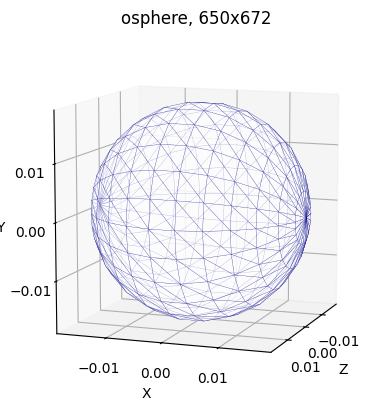

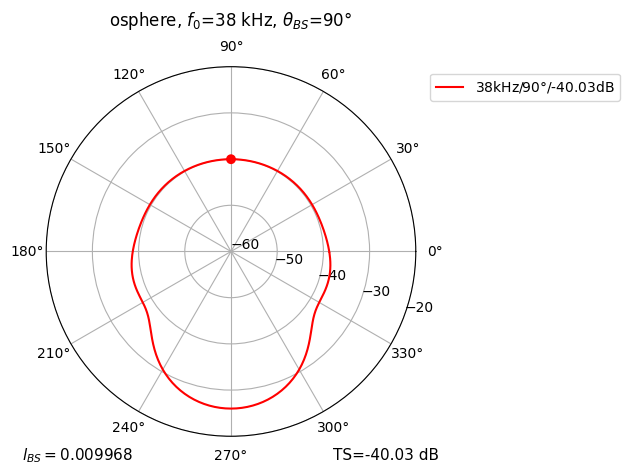

-0.01905	-0.00000	-0.00000	0.00000	0.00000	1.00000	1.00000
-0.01850	-0.00000	-0.00000	0.00912	0.00912	1.00000	1.00000
-0.01687	-0.00000	-0.00000	0.01771	0.01771	1.00000	1.00000
-0.01426	-0.00000	-0.00000	0.02526	0.02526	1.00000	1.00000
-0.01082	-0.00000	-0.00000	0.03136	0.03136	1.00000	1.00000
-0.00676	-0.00000	-0.00000	0.03562	0.03562	1.00000	1.00000
-0.00230	-0.00000	-0.00000	0.03782	0.03782	1.00000	1.00000
0.00230	0.00000	0.00000	0.03782	0.03782	1.00000	1.00000
0.00676	0.00000	0.00000	0.03562	0.03562	1.00000	1.00000
0.01082	0.00000	0.00000	0.03136	0.03136	1.00000	1.00000
0.01426	0.00000	0.00000	0.02526	0.02526	1.00000	1.00000
0.01687	0.00000	0.00000	0.01771	0.01771	1.00000	1.00000
0.01850	0.00000	0.00000	0.00912	0.00912	1.00000	1.00000
0.01905	0.00000	0.00000	-0.00000	-0.00000	1.00000	1.00000
0.002696 0.009596 0.009968 -40.03


In [2]:
# soft scattering using scipy lu decomposition
# MM 7.11.2026
#!pip install -q numpy numba scipy matplotlib
from numpy import pi, sqrt, exp, sin, cos, log10, array, zeros, linspace
from scipy.linalg import lu_factor, lu_solve
import matplotlib.pyplot as plt
# --- Green's matrix ---
def Green(x, y, k):
    m, n = len(x), len(y)
    G = zeros((m, n), dtype=complex) 
    for i in range(m):
        for j in range(n):
            r = sqrt(sum((x[i] - y[j]) ** 2))
            G[i][j] = exp(1j * k * r) / r / (4*pi) if r != 0 else k / 4 + 1j * k / (4*pi)
    return G
# --- input params ---
ff = [38.0e3]
th0 = [270]
c0 = 1480
t_v = 1    # triangles or vertices
p_p = 1    # plot and print or print only
# --- main ---
import time
tm = time.perf_counter()
from mm_util import mfrustum, osphere
xyzwh2 = osphere(0.01905)
v, e = mfrustum(xyzwh2)
n, m = len(v), len(e)
if t_v: x = [sum([array(v[e[i][j]]) / 3 for j in range(3)]) for i in range(m)]
else: x, m = array(v), len(v) # use vertices
r1 = [[cos(i * pi/180 + pi ), sin(i * pi/180 + pi), 0] for i in range(360)]
# --- solve ---
psc, lbs = [], []
for f0 in ff:
    k = 2*pi * f0 / c0
    G = Green(x, x, k)
    G1 = Green(x, r1, k) #[[exp(-1j * k * p @ r) / (4*pi) for r in r1] for p in x]
    u = lu_solve(lu_factor(G), G1)
    for th in th0:
        d = [cos(th * pi/180 + pi), sin(th * pi/180 + pi), 0]
        p_inc = array([exp(1j * k * p @ d) for p in x])
        psc.append(-p_inc @ u)
        lbs.append([f0, (th+180)%360, psc[-1][(th+180)%360], c0])
tm = time.perf_counter() - tm
# --- plot and print ---
from mm_util import plot_mesh, plot_lbs, print_lbs
id, fname, outpath = "outlines", "osphere", "out/"
if p_p:
    plot_mesh(v, e, fname, id+"_1", outpath)
    plot_lbs(psc, lbs, fname, id+"_3", outpath)
#for i,t in enumerate(lbs):
#    if t[1]==90: print_lbs([[psc[i][90]]], [lbs[i]], fname, n, m, id+"_4", outpath, tm)
for i in range(len(xyzwh2)):
    print("\t".join(["%.5f"%(x) for x in xyzwh2[i]]))
print("%.6f %.6f %.6f %.2f"%(lbs[0][2].real,lbs[0][2].imag,abs(lbs[0][2]),20*log10(abs(lbs[0][2]))))

